Temp = [ 50.    53.57  57.14  60.71  64.29  67.86  71.43  75.    78.57  82.14
  85.71  89.29  92.86  96.43 100.  ]


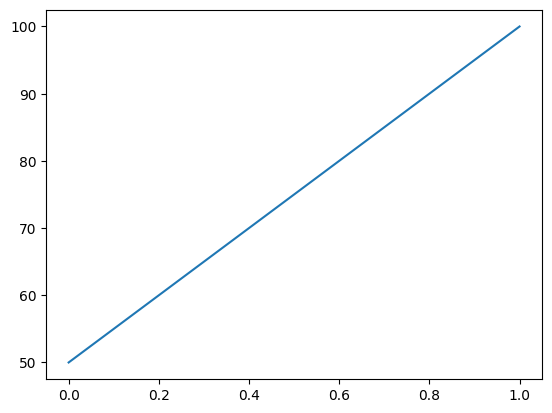

In [5]:
# Unit 4(a): The equilibrium temperature of a bar of length L with insulated horizontal sides and the ends maintained at fixed temperatures.
import numpy as np
import matplotlib.pyplot as plt

nodes = 15
pos = np.linspace(0, 1, nodes)
temp = np.zeros(nodes)

temp[0] = 50.0
temp[-1] = 100.0

diff = 1.0
while diff > 1e-5:
    old = temp.copy()
    for i in range(1, nodes - 1):
        temp[i] = 0.5 * (temp[i - 1] + temp[i + 1])
    diff = np.max(np.abs(temp - old))

print("Temp =", np.round(temp, 2))
plt.plot(pos, temp)
plt.show()

u(x) = [1.     0.9514 0.9071 0.8667 0.8303 0.7975 0.7683 0.7425 0.7199 0.7006
 0.6844 0.6713 0.6611 0.6538 0.6495 0.6481]


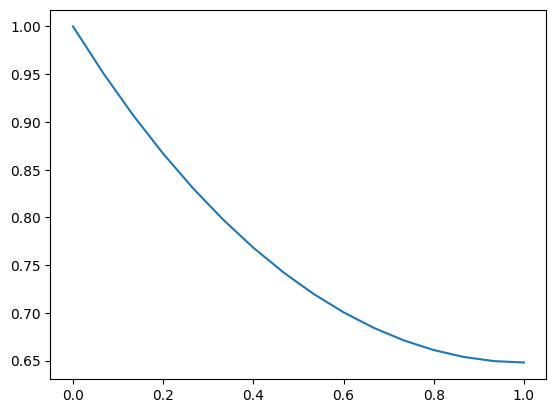

In [ ]:
# Unit 4(b): Solve for the steady state concentration profile y(x) in the reaction-diffusion problem given by y''(x) - y(x) = 0 with y(0) = 1, y'(1) = 0.
import numpy as np
import matplotlib.pyplot as plt

nodes = 16
pos = np.linspace(0, 1, nodes)
dx = pos[1] - pos[0]
u = np.zeros(nodes)

u[0] = 1.0

diff = 1.0
while diff > 1e-6:
    old = u.copy()
    for i in range(1, nodes - 1):
        u[i] = (u[i - 1] + u[i + 1]) / (2 + dx**2)
    u[-1] = (2 * u[-2]) / (2 + dx**2)
    diff = np.max(np.abs(u - old))

print("u(x) =", np.round(u, 4))
plt.plot(pos, u)
plt.show()

Center = 25.0


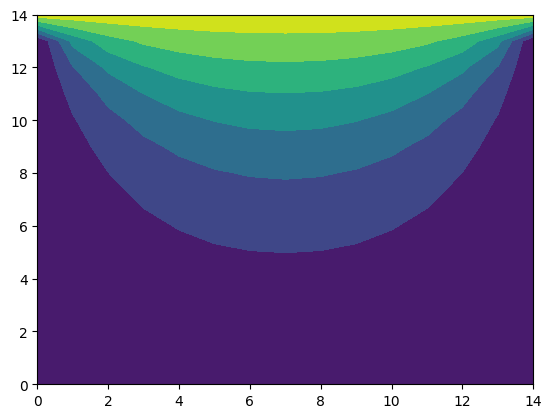

In [ ]:
# Unit 4(c): Use any numerical method to solve Laplace equation / Wave equation / Heat equation.
import numpy as np
import matplotlib.pyplot as plt

grid = 15
phi = np.zeros((grid, grid))
phi[-1, :] = 100.0

for itr in range(600):
    for r in range(1, grid - 1):
        for c in range(1, grid - 1):
            phi[r, c] = 0.25 * (phi[r + 1, c] + phi[r - 1, c] + phi[r, c + 1] + phi[r, c - 1])

print("Center =", np.round(phi[grid // 2, grid // 2], 2))
plt.contourf(phi)
plt.show()

In [ ]:
# Unit 4 (Shooting Method): Solve boundary value problem y'' + y = 0 with y(0) = 0, y(1) = 1.
def dy(x, y, z):
    return z

def dz(x, y, z):
    return -y

def shoot(slope):
    x, y, z, h = 0.0, 0.0, slope, 0.1
    for _ in range(10):
        k1 = h * dy(x, y, z)
        l1 = h * dz(x, y, z)
        k2 = h * dy(x + h/2, y + k1/2, z + l1/2)
        l2 = h * dz(x + h/2, y + k1/2, z + l1/2)
        k3 = h * dy(x + h/2, y + k2/2, z + l2/2)
        l3 = h * dz(x + h/2, y + k2/2, z + l2/2)
        k4 = h * dy(x + h, y + k3, z + l3)
        l4 = h * dz(x + h, y + k3, z + l3)
        y += (k1 + 2*k2 + 2*k3 + k4) / 6
        z += (l1 + 2*l2 + 2*l3 + l4) / 6
        x += h
    return y

s0, s1 = 0.5, 1.5
while abs(s1 - s0) > 1e-5:
    y0 = shoot(s0) - 1.0
    y1 = shoot(s1) - 1.0
    s_next = s1 - y1 * (s1 - s0) / (y1 - y0)
    s0, s1 = s1, s_next

print("Slope =", round(s1, 5))
print("y(1) =", round(shoot(s1), 5))

Slope = 1.1884
y(1) = 1.0
